# Fig. S2: further examples of interference fringes


    dI/dV line spectra measured across domain walls of the same flake (line spectra 986, 306, 660 and 402),
    and their derivatives along the sample bias.

    Processing, for every file: mean over the repetitions and the two sweep directions; normalization to
    the mean of the first and last current values; a running mean along distance and bias (7 pixels,
    3 pixels for 660); derivative along the bias per bias pixel. The windows are those of the figure.


Paper: Kandrai, K. *et al.* One-way electron mirrors from single-layer stacking shifts in rhombohedral graphite. Preprint at https://arxiv.org/abs/2610.20905 (2026).

In [1]:
import os
import sys
import requests
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import rhkpy
import xarray as xr

In [2]:
print('python', sys.version.split()[0])
print('numpy', np.__version__)
print('matplotlib', matplotlib.__version__)
print('rhkpy', rhkpy.__version__)
print('xarray', xr.__version__)

python 3.13.5
numpy 2.1.3
matplotlib 3.10.0
rhkpy 1.3.9
xarray 2025.4.0


In [3]:
# figure style of the paper: scienceplots if it is installed, plain matplotlib otherwise
try:
    import scienceplots  # noqa: F401
    plt.style.use(['science', 'no-latex', 'nature', 'std-colors'])
except ImportError:
    pass
matplotlib.rcParams['pdf.fonttype'] = 42   # editable text in Inkscape / Illustrator
matplotlib.rcParams['ps.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['figure.dpi'] = 110

In [4]:
# Data files are downloaded from Zenodo into DATA_DIR if they are not there yet.
ZENODO_RECORD = '23419464'   # record number of the data set, https://zenodo.org/records/<ZENODO_RECORD>
DATA_DIR = 'data'

FILES = ['MK_ABC_FLG_25_9K_2023_11_03_15_40_56_986.sm4', 'MK_ABC_FLG_25_9K_2023_10_31_18_04_35_306.sm4', 'MK_ABC_FLG_25_9K_2023_07_26_20_44_54_660.sm4', 'MK_ABC_FLG_25_9K_2023_10_26_17_45_53_402.sm4']


def get_data(filename, record=ZENODO_RECORD, data_dir=DATA_DIR):
    """Return the local path of a data file, downloading it from Zenodo first if needed."""
    path = os.path.join(data_dir, filename)
    if os.path.exists(path):
        return path
    os.makedirs(data_dir, exist_ok=True)
    url = f'https://zenodo.org/records/{record}/files/{requests.utils.quote(filename)}?download=1'
    print(f'Downloading {filename} ...')
    with requests.get(url, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(path, 'wb') as fh:
            for chunk in r.iter_content(chunk_size=1 << 20):
                fh.write(chunk)
    print(f'  saved to {path}')
    return path


for f in FILES:
    get_data(f)

In [5]:
def extent_of(da, xdim, ydim):
    """imshow extent (outer pixel edges) of an xarray DataArray with uniform coordinates."""
    x, y = da[xdim].values, da[ydim].values
    dx = (x[-1] - x[0]) / (x.size - 1)
    dy = (y[-1] - y[0]) / (y.size - 1)
    return [x[0] - dx / 2, x[-1] + dx / 2, y[0] - dy / 2, y[-1] + dy / 2]


def extent_xy(x, y):
    """imshow extent (outer pixel edges) for two uniform coordinate arrays."""
    dx = (x[-1] - x[0]) / (x.size - 1)
    dy = (y[-1] - y[0]) / (y.size - 1)
    return [x[0] - dx / 2, x[-1] + dx / 2, y[0] - dy / 2, y[-1] + dy / 2]

In [6]:
FILES_LS = {
    '986': 'MK_ABC_FLG_25_9K_2023_11_03_15_40_56_986.sm4',
    '306': 'MK_ABC_FLG_25_9K_2023_10_31_18_04_35_306.sm4',
    '660': 'MK_ABC_FLG_25_9K_2023_07_26_20_44_54_660.sm4',
    '402': 'MK_ABC_FLG_25_9K_2023_10_26_17_45_53_402.sm4',
}
line_specs = {key: rhkpy.rhkdata(get_data(fname)) for key, fname in FILES_LS.items()}
for key, ls in line_specs.items():
    print(key, dict(ls.spectra.sizes))

986 {'bias': 330, 'dist': 256, 'repetitions': 1, 'biasscandir': 2}
306 {'bias': 330, 'dist': 512, 'repetitions': 1, 'biasscandir': 2}
660 {'bias': 314, 'dist': 256, 'repetitions': 1, 'biasscandir': 2}
402 {'bias': 330, 'dist': 256, 'repetitions': 1, 'biasscandir': 2}


In [7]:
def average_and_normalize(line_spec, dims=('repetitions', 'biasscandir')):
    ls_mean = line_spec.spectra.mean(dim=list(dims)).sortby('bias')
    current_first = -ls_mean.current[0, :].data
    current_last = ls_mean.current[-1, :].data
    return 2 * ls_mean / (current_first + current_last)


ROLLS = {key: 7 for key in FILES_LS}
ROLLS['660'] = 3
line_specs_norm = {key: average_and_normalize(ls) for key, ls in line_specs.items()}
line_specs_norm_mean = {key: ls.rolling(dist=ROLLS[key], bias=ROLLS[key], center=True).mean()
                        for key, ls in line_specs_norm.items()}


def gradient_along_bias(lia, crop):
    grad = lia.copy(data=np.gradient(lia.data * 1000, axis=lia.dims.index('bias')))
    return grad[crop:-crop, crop:-crop]


gradients = {key: gradient_along_bias(ls.lia, crop=ROLLS[key] // 2)
             for key, ls in line_specs_norm_mean.items()}


def plot_lia(lia, cbar_label, cmap, vmin, vmax, dist_lim=(None, None), bias_lim=(None, None),
             title=None, figsize=(6, 4)):
    lia = lia.sel(dist=slice(*dist_lim), bias=slice(*bias_lim))
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(lia.transpose('bias', 'dist').values, cmap=cmap, aspect='auto', origin='lower',
                   extent=extent_of(lia, 'dist', 'bias'), vmin=vmin, vmax=vmax)
    ax.set_xlabel('distance (nm)'); ax.set_ylabel('sample bias (V)')
    if title:
        ax.set_title(title, fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label(cbar_label)
    return fig, ax, lia

## Derivative along the bias (panels d-f of Fig. S2 and the 402 line spectrum)

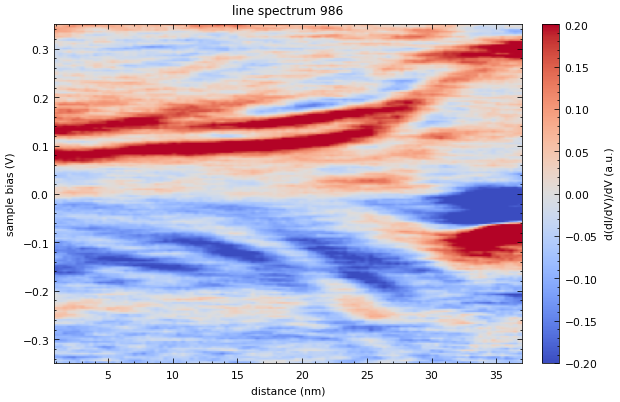

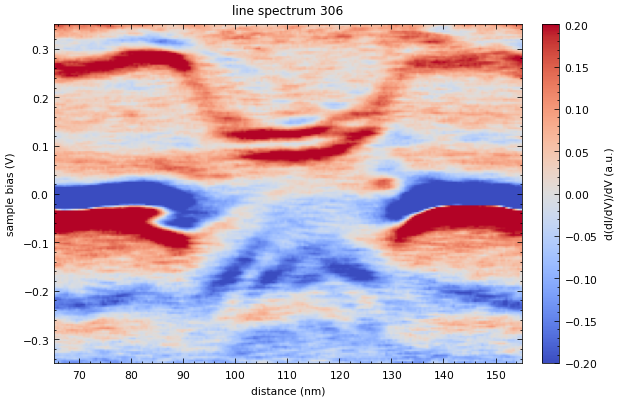

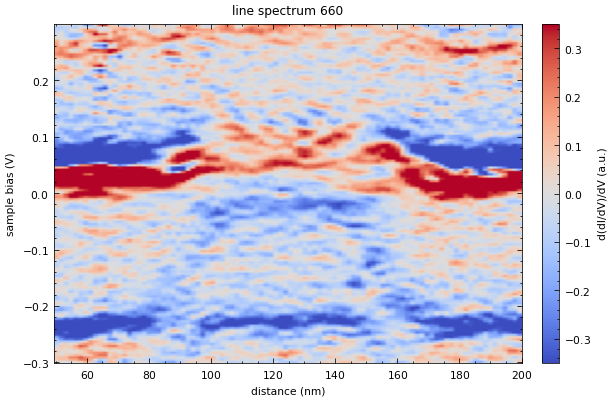

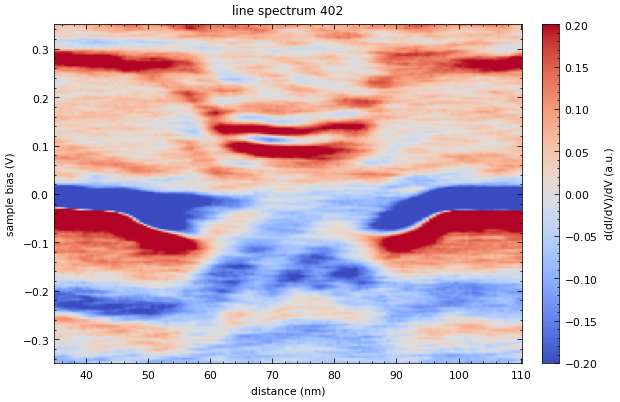

In [8]:
WINDOWS = {   # key: (dist window in nm, bias window in V, colour limit)
    '986': ((0, 37), (-0.35, 0.35), 0.2),
    '306': ((65, 155), (-0.35, 0.35), 0.2),
    '660': ((50, 200), (-0.3, 0.3), 0.35),
    '402': ((35, 110), (-0.35, 0.35), 0.2),
}
gradients_crop = {}
for key, (dist_lim, bias_lim, lim) in WINDOWS.items():
    fig, ax, gradients_crop[key] = plot_lia(gradients[key], 'd(dI/dV)/dV (a.u.)', 'coolwarm', -lim, lim,
                                            dist_lim=dist_lim, bias_lim=bias_lim, title=f'line spectrum {key}')
    plt.show()

## Normalized dI/dV in the same windows (panels a-c)

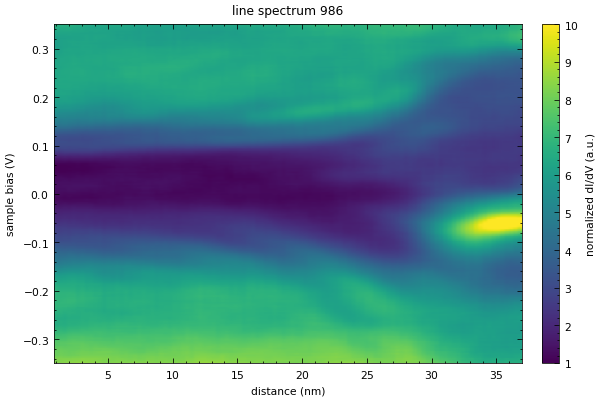

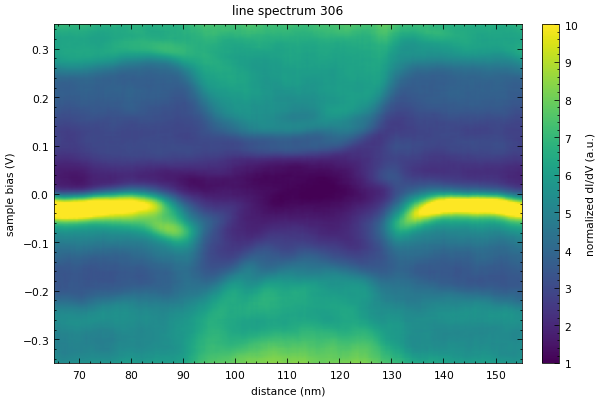

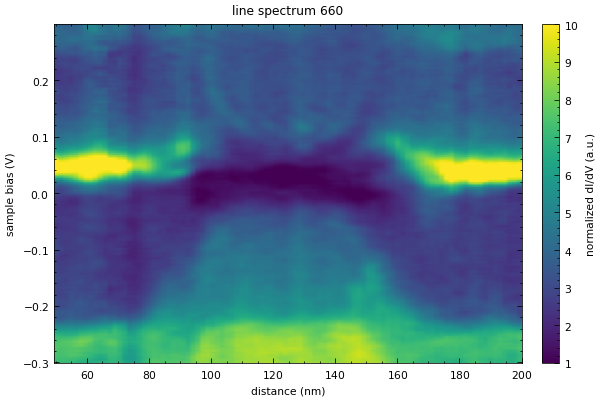

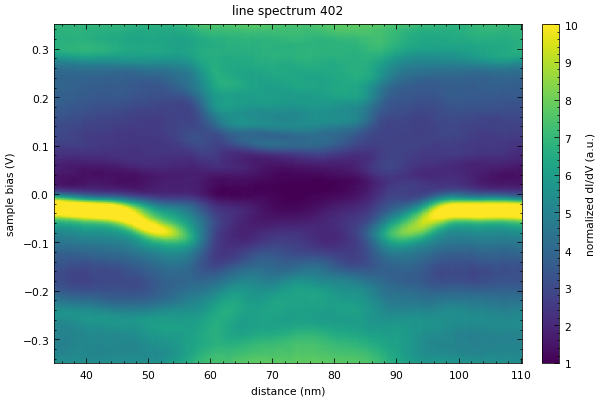

In [9]:
for key, grad_crop in gradients_crop.items():
    lia = line_specs_norm_mean[key].lia * 1000
    plot_lia(lia.sel(dist=grad_crop.dist, bias=grad_crop.bias), 'normalized dI/dV (a.u.)', 'viridis', 1, 10,
             title=f'line spectrum {key}')
    plt.show()